**I. Installation et téléchargement données**

Depuis les données World Bank, on télécharge les données relatives au chômage, au PIB/hab PPA et le RNB/hab PPA, celles de la population et les 65 ans et plus. Enfin, on récupère aussi les données concernant les dépenses pour la santé en pourcentage du PIB.
Nos données concernent les 38 pays de l'OCDE, sur une période d'étendant de 1991 à 2023.

In [21]:
!pip install wbgapi

import wbgapi as wb
import pandas as pd
from pathlib import Path

countries = ["AUS", "AUT", "BEL", "CAN", "CHL", "COL", "CRI", "CZE", "DNK", "EST", "FIN",
    "FRA", "DEU", "GRC", "HUN", "ISL", "IRL", "ISR", "ITA", "JPN", "KOR",
    "LVA", "LTU", "LUX", "MEX", "NLD", "NZL", "NOR", "POL", "PRT", "SVK",
    "SVN", "ESP", "SWE", "CHE", "TUR", "GBR", "USA"]

RAW_DIR = Path("data/raw")
RAW_DIR.mkdir(parents=True, exist_ok=True)

indicateurs = {
     "wb_chomage": "SL.UEM.TOTL.ZS",
    "wb_chomage_f": "SL.UEM.TOTL.FE.ZS",
    "wb_chomage_h": "SL.UEM.TOTL.MA.ZS",
    "wb_pib_hab_ppa": "NY.GDP.PCAP.PP.KD",
    "wb_rnb_hab_ppa": "NY.GNP.PCAP.PP.KD",
    "wb_pop": "SP.POP.TOTL",
    "wb_pop_65plus": "SP.POP.65UP.TO.ZS",
    "wb_dep_sante_pib": "SH.XPD.GHED.GD.ZS"
}

dfs = {}
for nom, code in indicateurs.items():
    chemin = RAW_DIR / f"{nom}.csv"
    if chemin.exists():
        df = pd.read_csv(chemin, index_col=0)
    else:
        df = wb.data.DataFrame(code, economy=countries, time=range(1991, 2024))
        df.to_csv(chemin)
    dfs[nom] = df.reset_index(names="economy")

taux_chomage = dfs["wb_chomage"]
taux_chomage_f = dfs["wb_chomage_f"]
taux_chomage_h = dfs["wb_chomage_h"]
pop = dfs["wb_pop"]
pop_65plus= dfs["wb_pop_65plus"]
pib_hab_ppa = dfs["wb_pib_hab_ppa"]
rnb_hab_ppa = dfs["wb_rnb_hab_ppa"]
dep_pub_sante = dfs["wb_dep_sante_pib"]


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


*Mise en forme et rassemblement des données*

Nos tableaux sont modifiés pour transformer les années en une colonne, puis on joint nos tableaux ensemble pour n'obtenir qu'un seul dataframe en joignant sur sur le couple (pays, année), afin d'obtenir l'ensemble des données pour tous les pays, sur l'ensemble de la période.

In [22]:
import pandas as pd
from functools import reduce

# On transforme notre tableau afin que les colonnes des années deviennent des valeurs de la colonne "year"
def en_long(df, nom_var):
    """Passe un tableau large (une colonne par année) en format long."""
    long = df.melt(id_vars=["economy"], var_name="year", value_name=nom_var)
    long["year"] = long["year"].astype(str).str.replace("YR", "").astype(int)

    return long

# Libellés des colonnes finales 
LABELS = {
    "wb_chomage": "Taux chômage",
    "wb_chomage_f": "Taux chômage F",
    "wb_chomage_h": "Taux chômage H",
    "wb_pib_hab_ppa":"PIB/hab ppa",
    "wb_rnb_hab_ppa" : "RNB/hab ppa",
    "wb_pop" : "Population",
    "wb_pop_65plus": "Pop 65+ (%)",
     "wb_dep_sante_pib": "Dépenses santé(% PIB)"
}

# Un tableau long par variable
dfs_long = [en_long(dfs[key], label) for key, label in LABELS.items()]

#Création d'un tableau qui associe les codes pays à leurs noms complets en anglais
noms = pd.DataFrame({
    "economy": ["AUS", "AUT", "BEL", "CAN", "CHL", "COL", "CRI", "CZE", "DNK", "EST", "FIN",
    "FRA", "DEU", "GRC", "HUN", "ISL", "IRL", "ISR", "ITA", "JPN", "KOR",
    "LVA", "LTU", "LUX", "MEX", "NLD", "NZL", "NOR", "POL", "PRT", "SVK",
    "SVN", "ESP", "SWE", "CHE", "TUR", "GBR", "USA"],

    "pays": ["Australia", "Austria", "Belgium", "Canada", "Chile", "Colombia", "Costa Rica",
    "Czechia", "Denmark", "Estonia", "Finland", "France", "Germany", "Greece",
    "Hungary", "Iceland", "Ireland", "Israel", "Italy", "Japan", "South Korea",
    "Latvia", "Lithuania", "Luxembourg", "Mexico", "Netherlands", "New Zealand",
    "Norway", "Poland", "Portugal", "Slovakia", "Slovenia", "Spain", "Sweden",
    "Switzerland", "Turkey", "United Kingdom", "United States"]
})

#On joint notre tableau pour ajouter les noms des pays, en regroupant par le code pays

df_eco = (reduce(lambda a, b: a.merge(b, on=["economy", "year"], how="outer"), dfs_long)
          .merge(noms, on="economy", how="left")
          .sort_values(["economy", "year"])
          .reset_index(drop=True))

df_eco = df_eco[["year", "pays", "economy"] + list(LABELS.values())]

df_eco.head(10)

,year,pays,economy,Taux chômage,Taux chômage F,Taux chômage H,PIB/hab ppa,RNB/hab ppa,Population,Pop 65+ (%),Dépenses santé(% PIB)
0,1991,Australia,AUS,9.586,9.164,9.887,35670.667864,30292.797235,17284036.0,11.237463,NaN
1,1992,Australia,AUS,10.733,9.935,11.305,35426.284829,30129.075368,17478635.0,11.413523,NaN
2,1993,Australia,AUS,10.879,10.004,11.509,36533.146828,31003.190328,17634808.0,11.579359,NaN
3,1994,Australia,AUS,9.724,9.370,9.983,37622.652477,31777.679986,17805468.0,11.724779,NaN
4,1995,Australia,AUS,8.473,8.111,8.743,38653.336678,32639.871049,18004882.0,11.846558,NaN
5,1996,Australia,AUS,8.509,8.240,8.711,39663.161773,33662.691064,18224767.0,11.962932,NaN
6,1997,Australia,AUS,8.367,8.079,8.584,40773.566052,34875.303258,18423037.0,12.069282,NaN
7,1998,Australia,AUS,7.684,7.336,7.948,42257.171812,36183.543200,18607584.0,12.165987,NaN
8,1999,Australia,AUS,6.876,6.662,7.039,43899.073794,37251.745011,18812264.0,12.251678,NaN
9,2000,Australia,AUS,6.288,6.070,6.459,45099.075210,38659.490992,19028802.0,12.338093,5.451437


**II. Première étude des données**

Dans un premier temps, on va s'intéresser aux données manquantes.

In [23]:
print(df_eco.shape)          
print(df_eco.isna().sum())

(1254, 11)
year                       0
pays                       0
economy                    0
Taux chômage               0
Taux chômage F             0
Taux chômage H             0
PIB/hab ppa                0
RNB/hab ppa              137
Population                 0
Pop 65+ (%)                0
Dépenses santé(% PIB)    342
dtype: int64


Grâce au tableau ci-dessus, on voit que deux de nos variables d'intérêt présentent des données manquantes : RNB/hab PPA, et dépenses en santé (en % du PIB)

In [24]:
trous = df_eco[df_eco["RNB/hab ppa"].isna()].groupby("pays")["year"].agg(["min", "max", "count"])
print(trous)

                 min   max  count
pays                             
Austria         1991  1994      4
Belgium         1991  1994      4
Czechia         1991  1994      4
Estonia         1991  1999      9
Finland         1991  1994      4
Greece          1991  2005     15
Hungary         1991  1998      8
Iceland         1991  1999      9
Ireland         1991  1994      4
Italy           1991  1994      4
Japan           1991  1993      3
Latvia          1991  1994      4
Lithuania       1991  1994      4
Norway          2023  2023      1
Poland          1991  1994      4
Portugal        1991  1994      4
Slovakia        1991  1994      4
Slovenia        1991  1994      4
Switzerland     1991  1994      4
Turkey          1991  2023     32
United Kingdom  1991  1998      8


Une grande partie des pays ont des données manquantes pour le RNB/hab PPA sur une même période (entre 1991 et 1994). 
-> La question se pose de savoir si cette variable peut être écartée du fait de sa corrélation avec le PIB/hab PPA qui lui, n'a pas de problème de données manquantes.

In [25]:
corr_pib_rnb = df_eco[["RNB/hab ppa", "PIB/hab ppa"]].corr().round(2)
print(corr_pib_rnb)

corr_par_pays = (
    df_eco.groupby("pays")[["RNB/hab ppa", "PIB/hab ppa"]]
    .apply(lambda d: d["RNB/hab ppa"].corr(d["PIB/hab ppa"]))
    .round(2)
    .rename("corr_RNB_PIB")
)
corr_par_pays=corr_par_pays = corr_par_pays.sort_values(ascending=True)
print(corr_par_pays)

             RNB/hab ppa  PIB/hab ppa
RNB/hab ppa         1.00         0.95
PIB/hab ppa         0.95         1.00
pays
Luxembourg        0.79
Iceland           0.81
Switzerland       0.81
Mexico            0.96
Norway            0.96
Italy             0.97
Japan             0.98
Portugal          0.98
Germany           0.99
Estonia           0.99
Belgium           0.99
Austria           0.99
Czechia           0.99
Costa Rica        0.99
Denmark           0.99
Australia         0.99
New Zealand       0.99
Finland           0.99
Ireland           0.99
Slovakia          0.99
United Kingdom    0.99
Canada            0.99
Colombia          1.00
Greece            1.00
Hungary           1.00
Latvia            1.00
Israel            1.00
Lithuania         1.00
Poland            1.00
Netherlands       1.00
France            1.00
Chile             1.00
South Korea       1.00
Slovenia          1.00
Sweden            1.00
Spain             1.00
United States     1.00
Turkey             NaN
Name: c

Sur les observations où les deux séries existent, la croissance du RNB/hab est
corrélée à celle du PIB/hab. Les corrélations par pays les plus faibles concernent le Luxembourg (0,79), l'Islande (0,81) et
la Suisse (0,81) : dans ces pays, le RNB contient une information conjoncturelle
que le PIB ne reflète pas entièrement. Cela pourrait s'expliquer par le fait que ces pays reçoivent d'importants revenus de l'étrangers, qui ne sont donc pas intégrés au PIB.
Nous écartons malgré tout le RNB, car il
est manquant pour la Turquie et pour plusieurs pays entre 1991 et 1994, ce qui
déséquilibrerait le panel.

Suppression variable RNB/hab PPA 

In [26]:
from pathlib import Path

PROCESSED_DIR = Path("data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

df_eco = df_eco.drop(columns=["RNB/hab ppa"])
df_eco.to_csv(PROCESSED_DIR/ "wb_eco_clean.csv", index=False)

*Ajout de variables qui vont nous indiquer la variation des variables*

Il nous semblait pertinent de ne pas seulement prendre en compte la valeur du PIB/hab, mais surtout s'intéresser aux variations de celui-ci.

In [27]:
df_eco["Croissance pib/hab"] = df_eco.groupby("economy")["PIB/hab ppa"].pct_change() * 100
df_eco["Variation taux chômage"] = df_eco.groupby("economy")["Taux chômage"].diff()
df_eco["Variation taux chômage - F"] = df_eco.groupby("economy")["Taux chômage F"].diff()
df_eco["Variation taux chômage - M"] = df_eco.groupby("economy")["Taux chômage H"].diff()

df_eco.head(10)

,year,pays,economy,Taux chômage,Taux chômage F,Taux chômage H,PIB/hab ppa,Population,Pop 65+ (%),Dépenses santé(% PIB),Croissance pib/hab,Variation taux chômage,Variation taux chômage - F,Variation taux chômage - M
0,1991,Australia,AUS,9.586,9.164,9.887,35670.667864,17284036.0,11.237463,NaN,NaN,NaN,NaN,NaN
1,1992,Australia,AUS,10.733,9.935,11.305,35426.284829,17478635.0,11.413523,NaN,-0.685109,1.147,0.771,1.418
2,1993,Australia,AUS,10.879,10.004,11.509,36533.146828,17634808.0,11.579359,NaN,3.124409,0.146,0.069,0.204
3,1994,Australia,AUS,9.724,9.370,9.983,37622.652477,17805468.0,11.724779,NaN,2.982239,-1.155,-0.634,-1.526
4,1995,Australia,AUS,8.473,8.111,8.743,38653.336678,18004882.0,11.846558,NaN,2.739531,-1.251,-1.259,-1.240
5,1996,Australia,AUS,8.509,8.240,8.711,39663.161773,18224767.0,11.962932,NaN,2.612517,0.036,0.129,-0.032
6,1997,Australia,AUS,8.367,8.079,8.584,40773.566052,18423037.0,12.069282,NaN,2.799586,-0.142,-0.161,-0.127
7,1998,Australia,AUS,7.684,7.336,7.948,42257.171812,18607584.0,12.165987,NaN,3.638646,-0.683,-0.743,-0.636
8,1999,Australia,AUS,6.876,6.662,7.039,43899.073794,18812264.0,12.251678,NaN,3.885499,-0.808,-0.674,-0.909
9,2000,Australia,AUS,6.288,6.070,6.459,45099.075210,19028802.0,12.338093,5.451437,2.733546,-0.588,-0.592,-0.580


*Exportation du tableau pour l'utiliser par la suite, pour étudier le lien avec la mortalité*

In [35]:
df_eco.to_csv(PROCESSED_DIR / "wb_eco_clean.csv", index=False)

*Vérification de l'export/import*

In [36]:
df_eco_verif = pd.read_csv("data/processed/wb_eco_clean.csv")
df_eco_verif.head(10)

,year,pays,economy,Taux chômage,Taux chômage F,Taux chômage H,PIB/hab ppa,Population,Pop 65+ (%),Dépenses santé(% PIB),Croissance pib/hab,Variation taux chômage,Variation taux chômage - F,Variation taux chômage - M
0,1991,Australia,AUS,9.586,9.164,9.887,35670.667864,17284036.0,11.237463,NaN,NaN,NaN,NaN,NaN
1,1992,Australia,AUS,10.733,9.935,11.305,35426.284829,17478635.0,11.413523,NaN,-0.685109,1.147,0.771,1.418
2,1993,Australia,AUS,10.879,10.004,11.509,36533.146828,17634808.0,11.579359,NaN,3.124409,0.146,0.069,0.204
3,1994,Australia,AUS,9.724,9.370,9.983,37622.652477,17805468.0,11.724779,NaN,2.982239,-1.155,-0.634,-1.526
4,1995,Australia,AUS,8.473,8.111,8.743,38653.336678,18004882.0,11.846558,NaN,2.739531,-1.251,-1.259,-1.240
5,1996,Australia,AUS,8.509,8.240,8.711,39663.161773,18224767.0,11.962932,NaN,2.612517,0.036,0.129,-0.032
6,1997,Australia,AUS,8.367,8.079,8.584,40773.566052,18423037.0,12.069282,NaN,2.799586,-0.142,-0.161,-0.127
7,1998,Australia,AUS,7.684,7.336,7.948,42257.171812,18607584.0,12.165987,NaN,3.638646,-0.683,-0.743,-0.636
8,1999,Australia,AUS,6.876,6.662,7.039,43899.073794,18812264.0,12.251678,NaN,3.885499,-0.808,-0.674,-0.909
9,2000,Australia,AUS,6.288,6.070,6.459,45099.075210,19028802.0,12.338093,5.451437,2.733546,-0.588,-0.592,-0.580


Statistiques descriptives 

In [30]:
variables_interet=["Taux chômage",
    "Taux chômage F",
    "Taux chômage H",
    "PIB/hab ppa",  
    "Population",
    "Pop 65+ (%)", "Dépenses santé(% PIB)"]
    
df_eco[variables_interet].describe(include="all")

,Taux chômage,Taux chômage F,Taux chômage H,PIB/hab ppa,Population,Pop 65+ (%),Dépenses santé(% PIB)
count,1254.000000,1254.000000,1254.000000,1254.000000,1.254000e+03,1254.000000,912.000000
mean,7.673285,8.232442,7.325222,43757.373618,3.319648e+07,14.682119,5.935732
std,4.096869,4.804585,3.924215,21762.823507,5.390354e+07,4.471525,1.780939
min,1.100000,1.085000,1.114000,9996.097860,2.577970e+05,3.981459,1.881744
25%,4.681750,4.865000,4.480500,28894.028201,5.067935e+06,12.065064,4.591363
50%,6.852000,7.032000,6.507500,42203.809597,1.032811e+07,15.044686,5.964305
75%,9.676250,10.479500,9.026000,54920.421745,4.634384e+07,17.571390,7.241970
max,27.686000,31.650000,25.605000,138683.319853,3.367551e+08,29.561810,10.600080


Grâce au tableau des statistiques descriptives ci-dessus, nous avons des premières informations sur nos variables d'intérêts, pour tous les pays et années confondues.
Ce tableau permet un premier contrôle pour repérer d'éventuelles valeurs abberantes. Les valeurs (minimum, maximum, moyenne, médiane) semblent cohérentes.
Le chômage féminin semble plus fort que le chômage masculin, la moyenne et la médiane sont supérieures, et la valeur maximale est elle ausis plus importante.
En terme de population, la moyenne et la médiane sont très éloignée, ce qui suggère que certains pays tirent fortement la moyenne vers le haut.

**III. Visualisation des données économiques d'intérêt**

*On représente la distribution des moyennes des variables, calculées par économie.*

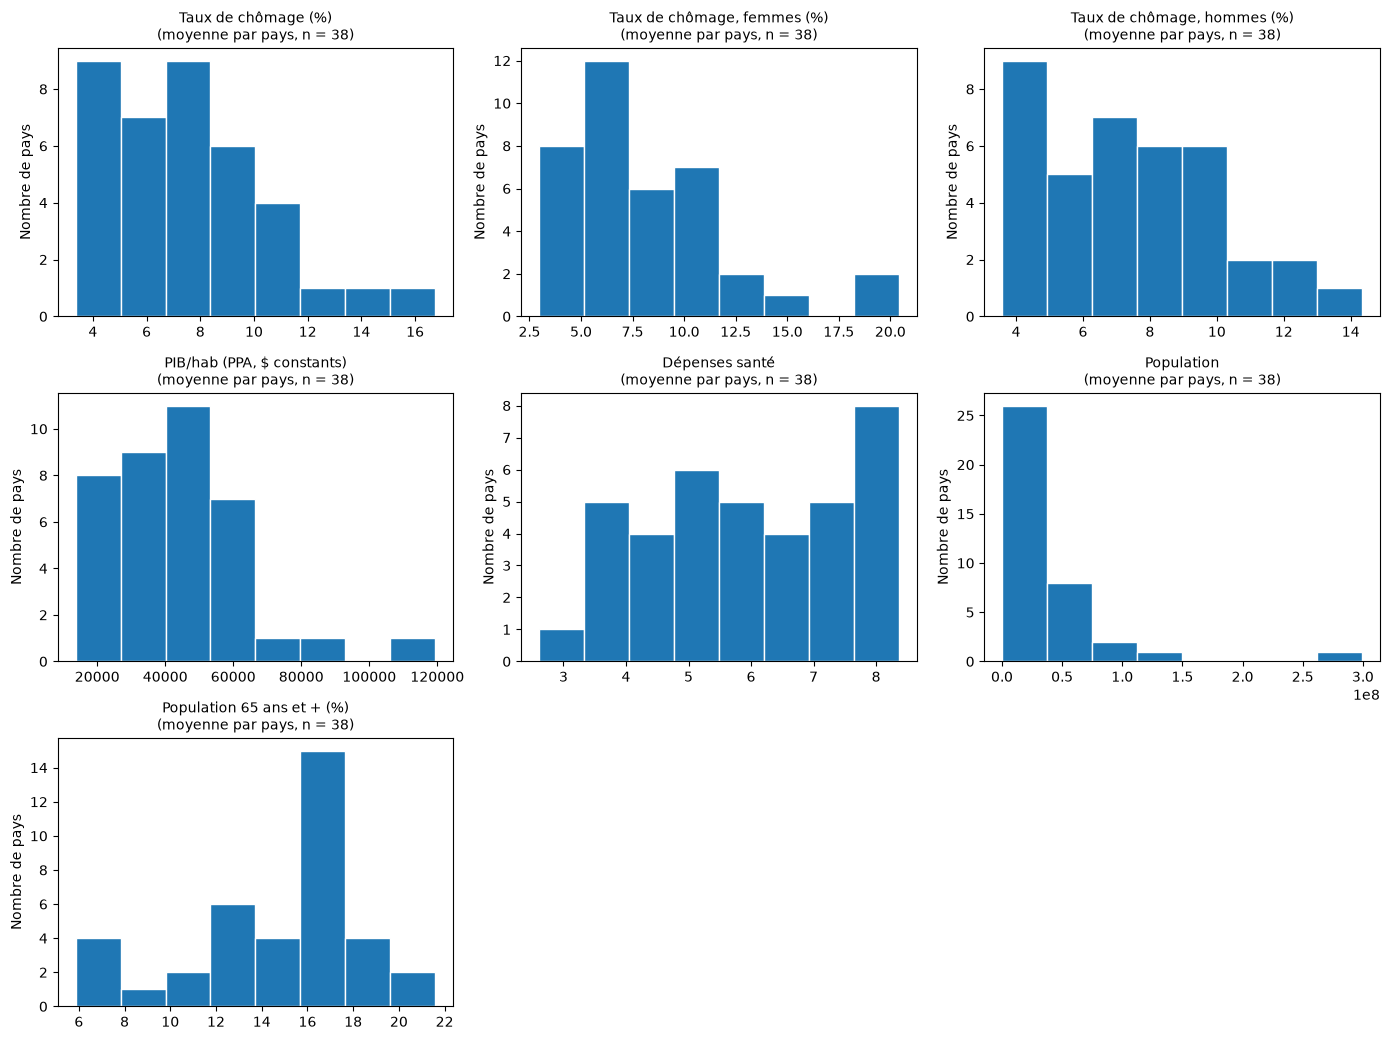

In [31]:
import matplotlib.pyplot as plt
import numpy as np

variables = {
    "Taux chômage": "Taux de chômage (%)",
    "Taux chômage F": "Taux de chômage, femmes (%)",
    "Taux chômage H":  "Taux de chômage, hommes (%)",
    "PIB/hab ppa":"PIB/hab (PPA, $ constants)",
    "Dépenses santé(% PIB)": "Dépenses santé",
    "Population":"Population",
    "Pop 65+ (%)":"Population 65 ans et + (%)",
}

n = len(variables)
ncols = 3
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.5 * nrows))
axes = axes.flatten()

for ax, (col, titre) in zip(axes, variables.items()):
    moyennes = df_eco.groupby("economy")[col].mean().dropna()
    ax.hist(moyennes, bins=8, edgecolor="white")
    ax.set_title(f"{titre}\n(moyenne par pays, n = {len(moyennes)})", fontsize=10)
    ax.set_ylabel("Nombre de pays")

for ax in axes[n:]:       
    ax.axis("off")

plt.tight_layout()
plt.show()

Les histogrammes ci-dessus décrivent la répartition des 38 pays selon la moyenne de chaque variable sur la période. Les taux de chômage présentent une distribution asymétrique à droite : la plupart des pays ont un taux moyen compris entre 4 % et 10 %, tandis que quelques pays affichent des niveaux nettement plus élevés, en particulier pour le chômage féminin (jusqu'à environ 20 %). Le PIB par habitant est lui aussi asymétrique, avec quelques pays très riches. La population est la variable la plus déséquilibrée : une grande majorité de pays compte moins de 40 millions d'habitants, tandis qu'un pays dépasse les 300 millions. Les dépenses de santé sont réparties de façon plus homogène entre 3 % et 8 % du PIB. La part de la population âgée de 65 ans et plus, moyennée par pays, présente une distribution asymétrique à gauche. La plupart des pays se concentrent entre 12 % et 18 %, avec un regroupement marqué autour de 16-18 % (15 pays sur 38). Un petit groupe de quatre pays se distingue par une proportion de personnes âgées beaucoup plus faible, comprise entre 6 % et 8 %. Cette hétérogénéité reflète des degrés de vieillissement très différents d'un pays à l'autre.

*On représente l'évolution de la moyenne annuelle de chaque variable.*

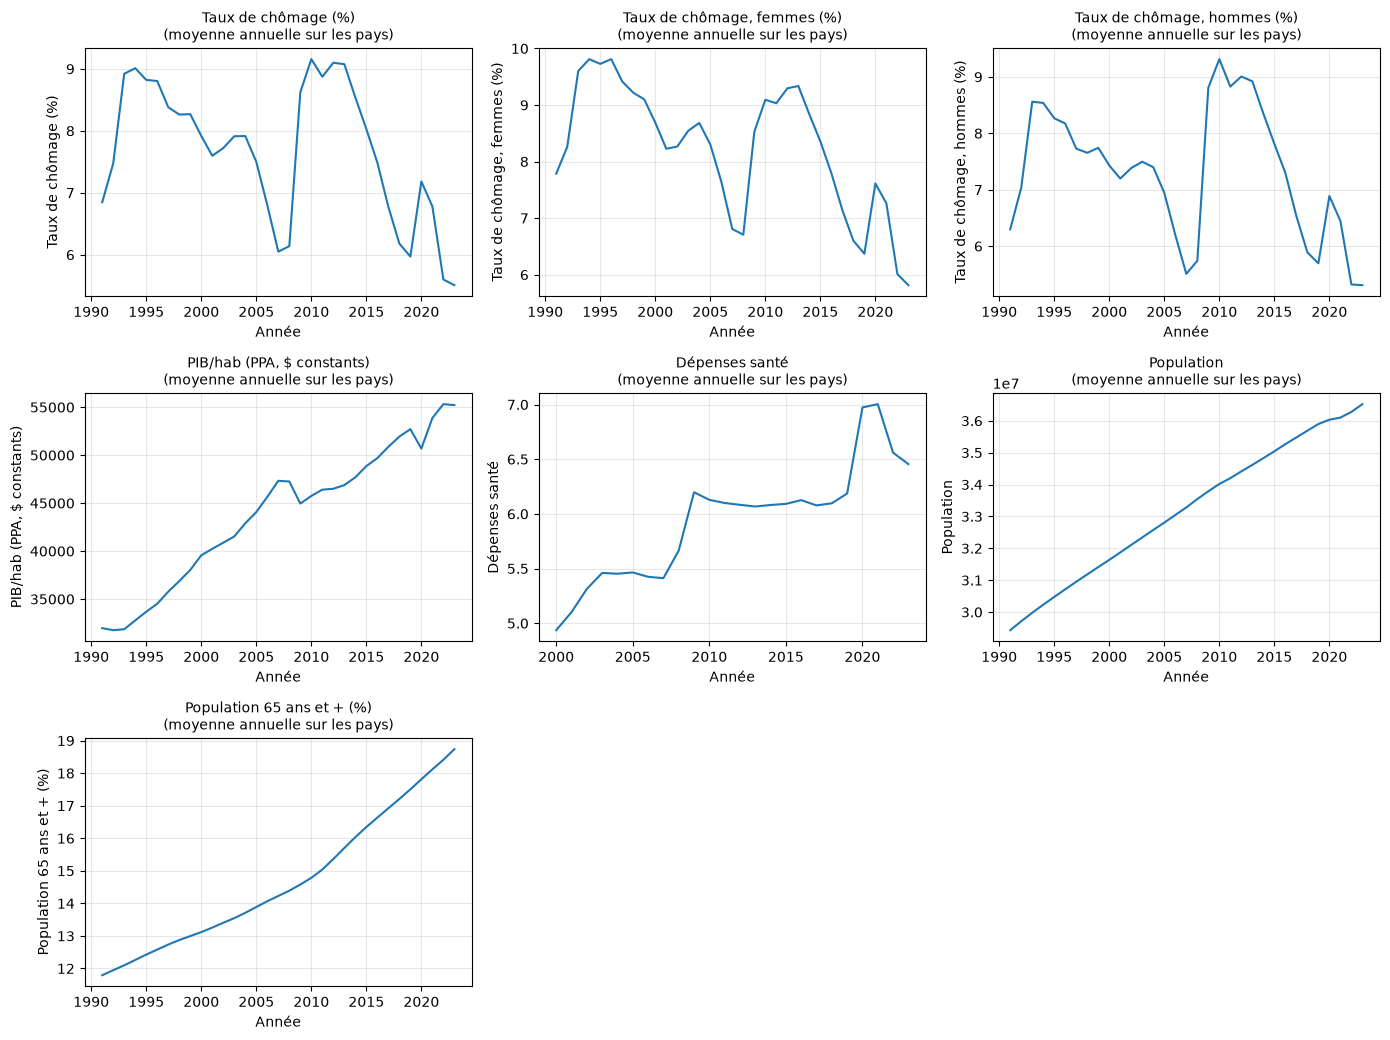

In [32]:
n = len(variables)
ncols = 3
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.5 * nrows))
axes = axes.flatten()

for ax, (col, titre) in zip(axes, variables.items()):
    serie = df_eco.groupby("year")[col].mean()
    serie.plot(ax=ax)
    ax.set_title(f"{titre}\n(moyenne annuelle sur les pays)", fontsize=10)
    ax.set_xlabel("Année")
    ax.set_ylabel(titre)
    ax.grid(alpha=0.3)

for ax in axes[n:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

Tout d'abord, les trois courbes de chômage suivent une tendance très semblable : un premier pic entre 1992 et 1998, un second entre 2008 et 2015, et enfin un troisième entre 2019 et 2021.
Le PIB/hab suit une croissance assez linéaire avec néanmoins deux interruptions avec une chute du PIB par habitant en 2007 et 2020.
Les dépenses en santé (en pourcentage du PIB) ressemblent à des plateaux. Une première hausse au début des années 2000 pour atteindre 5.5%, une seconde hausse en 2006 pour atteindre 6.1% du PIB, et enfin une hausse en 2020 pour atteindre 7% du PIB, mais qui est redescendu à 6.5% du PIB en 2021-2022.
Enfin, la population suit une croissance linéaire. La part de plus de 65 ans dans les pays est en croissance, avec une pente qui augmente à partir de 2010. Alors que les plus de 65 ans représentaient 12% de la population en 1990, ils représentent en 2023 presque 19% de la population, ce qui s'explique par le vieillissement démographiques des pays de l'OCDE.

*Trajectoires des pays*

Afin d'avoir des graphiques observables, on choisit de colorer seulement 6 pays parmis les 38, afin d'étudier les différences au sein de ces pays. Les autres pays sont tracés en gris

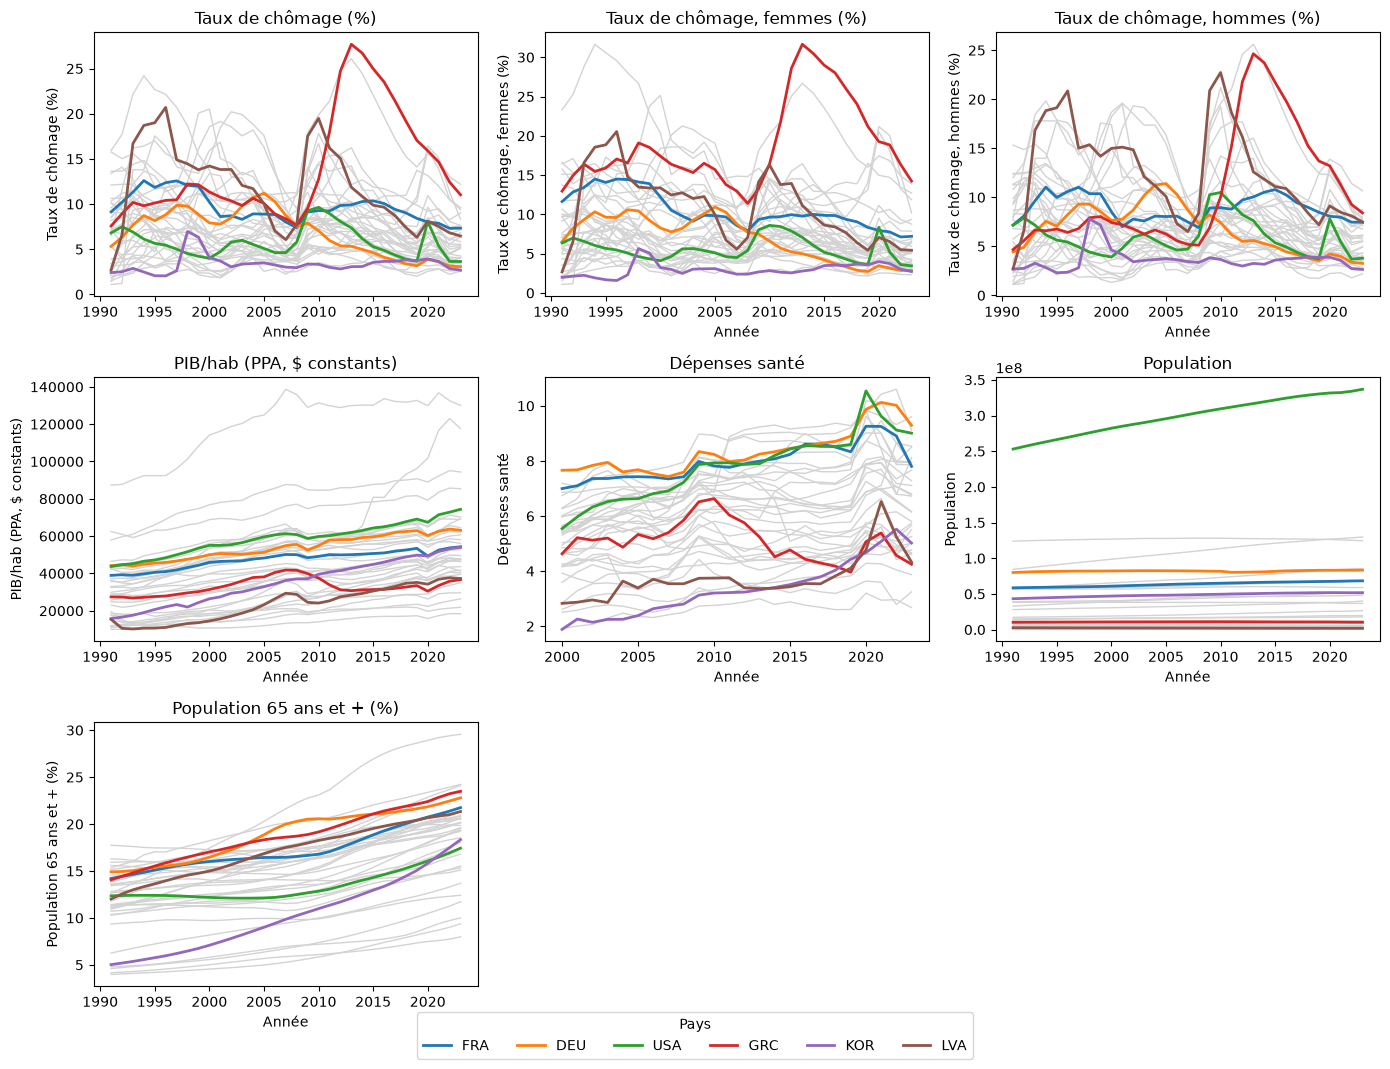

In [33]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

mis_en_avant = ["FRA", "DEU", "USA", "GRC", "KOR", "LVA"]
couleurs = dict(zip(mis_en_avant, plt.cm.tab10.colors))  

n = len(variables)
ncols = 3
nrows = -(-n // ncols)  # division arrondie au supérieur

fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.5 * nrows))
axes = axes.flatten()

for ax, (col, titre) in zip(axes, variables.items()):
    pivot = df_eco.pivot(index="year", columns="economy", values=col)

    # fond : tous les autres pays en gris
    pivot.drop(columns=mis_en_avant).plot(ax=ax, color="lightgrey", legend=False, linewidth=1)
    # premier plan : pays mis en avant, avec leur couleur fixe
    pivot[mis_en_avant].plot(ax=ax, color=[couleurs[p] for p in mis_en_avant],
                             legend=False, linewidth=2)

    ax.set_title(titre)
    ax.set_xlabel("Année")
    ax.set_ylabel(titre)

for ax in axes[n:]:
    ax.axis("off")

# légende construite à la main, indépendante des subplots
handles = [Line2D([0], [0], color=couleurs[p], linewidth=2) for p in mis_en_avant]
fig.legend(handles, mis_en_avant, title="Pays", loc="lower center",
           ncol=len(mis_en_avant), bbox_to_anchor=(0.5, -0.02))

plt.tight_layout()
plt.show()

Pour mieux visualiser l'hétérogénéité des trajectoires, six pays sont mis en avant sur fond gris représentant les autres pays.
Les 6 pays choisis sont la France, l'Allemagne, les Etats-Unis, la Grèce, la Corée du Sud, et la Lettonie. 
La Grèce se distingue par la crise de 2008-2015 : le chômage atteint près de 28 % en 2013, plus de 30% chez les femmes et le PIB par habitant recule. 
La Lettonie a aussi subi un chômage élevé sur la période 2008-2013, particulièrement chez les hommes, où il atteint près de 23% au pic tandis qu'il ne dépasse pas 15% chez les femmes durant la même période. Cela est d'autant plus intéressant du fait que durant le pic de 1995, ce taux était très proche entre hommes et femmes.
La Corée du Sud présente un chômage faible et stable mais un vieillissement rapide, la part des 65 ans et plus passant d'environ 5 % en 1991 à plus de 17 % en 2023. Néanmoins ce pourcentage est encore inférieur à la plupart des autres pays d'étude.
Les États-Unis se caractérisent par une population nettement supérieure aux autres pays et qui continue de croître, tandis que celles des autres pays sont plus plates, un PIB par habitant élevé et des dépenses de santé parmi les plus fortes, dépassant la France et l'Allemagne vers 2018. 
Enfin, la France et l'Allemagne suivent des trajectoires proches, avec un chômage plus bas en Allemagne depuis 2008 environ.

Corrélation entre les variables

In [38]:
cols = ["Taux chômage", "Taux chômage F", "Taux chômage H","PIB/hab ppa", "Population", "Pop 65+ (%)","Dépenses santé(% PIB)", "Croissance pib/hab", "Variation taux chômage"]
corr = df_eco[cols].corr().round(2)
corr

,Taux chômage,Taux chômage F,Taux chômage H,PIB/hab ppa,Population,Pop 65+ (%),Dépenses santé(% PIB),Croissance pib/hab,Variation taux chômage
Taux chômage,1.00,0.95,0.97,-0.39,-0.10,-0.03,-0.17,0.01,0.15
Taux chômage F,0.95,1.00,0.84,-0.39,-0.09,-0.07,-0.21,0.02,0.11
Taux chômage H,0.97,0.84,1.00,-0.36,-0.10,0.00,-0.14,0.00,0.19
PIB/hab ppa,-0.39,-0.39,-0.36,1.00,-0.01,0.41,0.40,-0.10,-0.05
Population,-0.10,-0.09,-0.10,-0.01,1.00,-0.05,0.16,-0.05,-0.01
Pop 65+ (%),-0.03,-0.07,0.00,0.41,-0.05,1.00,0.54,-0.11,-0.07
Dépenses santé(% PIB),-0.17,-0.21,-0.14,0.40,0.16,0.54,1.00,-0.28,0.11
Croissance pib/hab,0.01,0.02,0.00,-0.10,-0.05,-0.11,-0.28,1.00,-0.56
Variation taux chômage,0.15,0.11,0.19,-0.05,-0.01,-0.07,0.11,-0.56,1.00


Grâce au tableau de corrélation ci-dessus, on constate tout d'abord que les indicateurs du chômages sont fortement corrélés positivement, ce qui semble cohérent.
Le PIB/hab est moyennement et négativement corrélé au chômage (-0.39). Il est aussi moyennement et positivement corrélés au dépenses de santé.